# IS353 - Lab 5a: Community Detection

**MSSV:** 23520588

Đồ thị chính là Zachary Karate Club: 34 đỉnh, 78 cạnh, hai phe quanh Mr. Hi (đỉnh 0) và Officer (đỉnh 33). Mỗi phe 17 người. Modularity của đúng lần tách lịch sử này là Q = 0.3914.

Modularity Q cao khi trong cụm có nhiều cạnh hơn mức một đồ thị ngẫu nhiên cùng bậc. Các thuật toán dưới đây không được cho biết phe nào. Câu hỏi là chúng cắt ra bao nhiêu cụm, Q bằng bao nhiêu, và cụm đó có khớp hai phe hay không.


## Cài thư viện


In [1]:
%pip install networkx matplotlib numpy scipy pandas


   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.7 MB 5.0 MB/s eta 0:00:02
   --------- ------------------------------ 2.6/10.7 MB 6.4 MB/s eta 0:00:02
   -------------- ------------------------- 3.9/10.7 MB 7.2 MB/s eta 0:00:01
   ---------------------- ----------------- 6.0/10.7 MB 7.4 MB/s eta 0:00:01
   ---------------------------------- ----- 9.2/10.7 MB 9.0 MB/s eta 0:00:01
   -------------------------------------- - 10.2/10.7 MB 8.6 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 8.2 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import


In [2]:
%matplotlib inline

import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from networkx.algorithms.community import (
    girvan_newman,
    greedy_modularity_communities,
    label_propagation_communities,
    louvain_communities,
    modularity as nx_modularity,
)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 13,
})


## Hàm dùng chung


In [3]:
def lab_dir() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd() / "BT" / "Lab5a",
        Path(r"d:/Study/IS353/BT/Lab5a"),
    ]
    for folder in candidates:
        if (folder / "requirement.txt").exists() and "Lab5a" in str(folder):
            return folder
    raise FileNotFoundError("Không thấy requirement.txt của Lab 5a.")


LAB = lab_dir()
FIG = LAB / "figures"
FIG.mkdir(exist_ok=True)


def partition_stats(G, parts):
    parts = [set(c) for c in parts]
    sizes = sorted((len(c) for c in parts), reverse=True)
    return {"k": len(parts), "sizes": sizes, "Q": nx_modularity(G, parts), "parts": parts}


def print_stats(label, st, elapsed=None):
    line = f"{label}: k={st['k']}, sizes={st['sizes']}, Q={st['Q']:.4f}"
    if elapsed is not None:
        line += f", time={elapsed:.4f}s"
    print(line)


def draw_partition(G, parts, pos, title, path):
    node2com = {}
    for i, com in enumerate(parts):
        for v in com:
            node2com[v] = i
    colors = [node2com[n] for n in G.nodes()]
    fig, ax = plt.subplots(figsize=(8, 6))
    nx.draw(
        G,
        pos,
        ax=ax,
        with_labels=True,
        node_color=colors,
        cmap=plt.cm.Set2,
        node_size=280,
        font_size=8,
        edge_color="#bbbbbb",
    )
    ax.set_title(title)
    ax.set_axis_off()
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


def spectral_two_way(G):
    # Fiedler: vector riêng ứng với trị riêng nhỏ thứ hai của normalized Laplacian.
    # Quét theo thứ tự giá trị này và giữ nhát cắt 2 cụm có Q cao nhất.
    nodes = list(G.nodes())
    L = nx.normalized_laplacian_matrix(G, nodelist=nodes).astype(float)
    if G.number_of_nodes() <= 400:
        vals, vecs = np.linalg.eigh(np.asarray(L.todense()))
        fiedler = np.asarray(vecs[:, 1]).flatten()
    else:
        import scipy.sparse.linalg as spla

        vals, vecs = spla.eigsh(L, k=2, which="SM")
        fiedler = np.asarray(vecs[:, int(np.argmax(vals))]).flatten()
    order = [nodes[i] for i in np.argsort(fiedler)]
    m = G.number_of_edges()
    deg = dict(G.degree())
    in_left = set()
    internal = 0
    cut = 0
    vol = 0
    best_Q = -1.0
    best_cut = 1
    for t, node in enumerate(order):
        for nbr in G.neighbors(node):
            if nbr in in_left:
                cut -= 1
                internal += 1
            else:
                cut += 1
        vol += deg[node]
        in_left.add(node)
        if t == len(order) - 1:
            break
        e_left = internal / m
        e_right = (m - internal - cut) / m
        a_left = vol / (2 * m)
        a_right = 1 - a_left
        Q = (e_left - a_left**2) + (e_right - a_right**2)
        if Q > best_Q:
            best_Q = Q
            best_cut = t + 1
    left = set(order[:best_cut])
    right = set(order[best_cut:])
    return [left, right]


results = {}


## Karate Club

`nx.karate_club_graph()` gắn sẵn thuộc tính `club`: Mr. Hi hoặc Officer. Đó là phe sau khi câu lạc bộ tách, dùng để chấm phương pháp nào khớp thực tế. Các thuật toán không đọc thuộc tính này.


nodes=34, edges=78
Mr. Hi 17, Officer 17, Q=0.3914


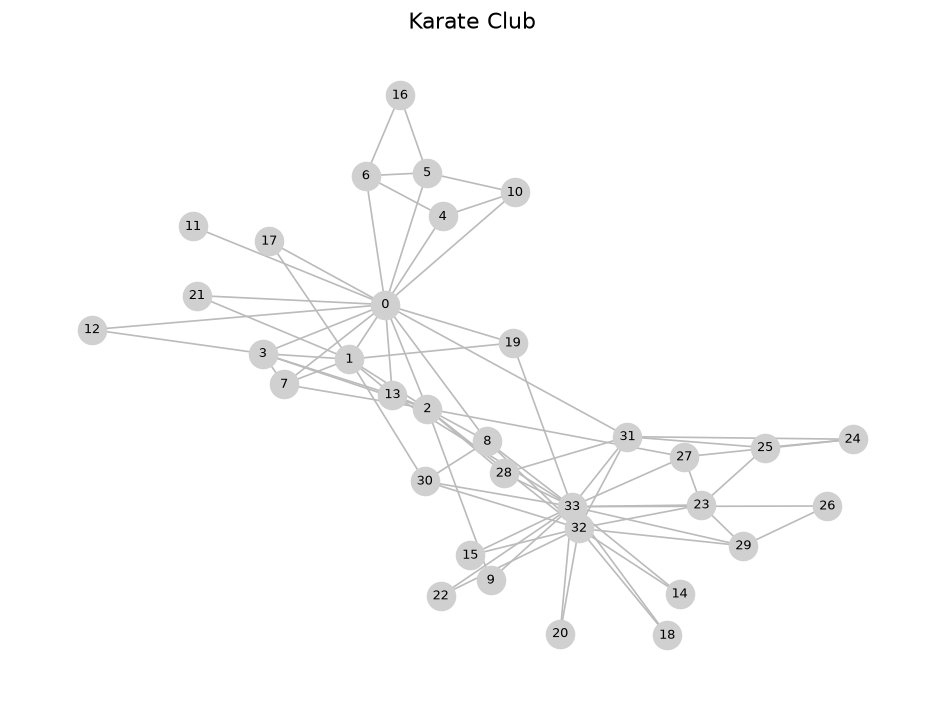

In [4]:
karate = nx.karate_club_graph()
club = nx.get_node_attributes(karate, "club")
truth = [
    {n for n, name in club.items() if name == "Mr. Hi"},
    {n for n, name in club.items() if name == "Officer"},
]
print(f"nodes={karate.number_of_nodes()}, edges={karate.number_of_edges()}")
print(f"Mr. Hi {len(truth[0])}, Officer {len(truth[1])}, Q={nx_modularity(karate, truth):.4f}")

pos = nx.spring_layout(karate, seed=42)
fig, ax = plt.subplots(figsize=(8, 6))
nx.draw(karate, pos, ax=ax, with_labels=True, node_color="#d0d0d0", node_size=280, font_size=8, edge_color="#bbbbbb")
ax.set_title("Karate Club")
ax.set_axis_off()
fig.tight_layout()
fig.savefig(FIG / "karate_base.png", bbox_inches="tight")
plt.show()


## Label Propagation


Label Propagation: k=3, sizes=[16, 15, 3], Q=0.3095, time=0.0039s


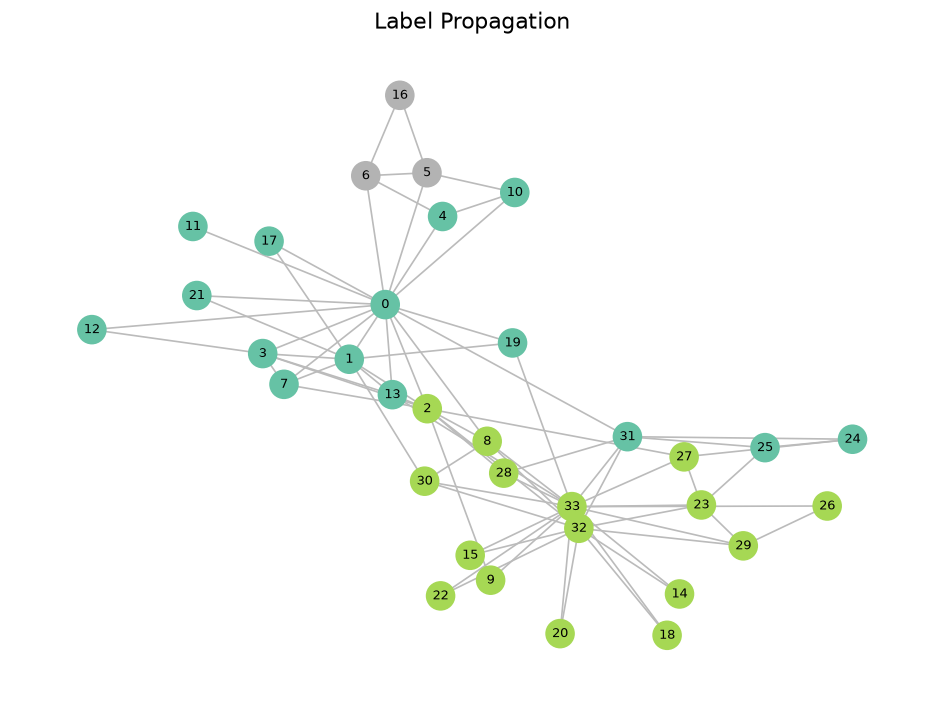

In [5]:
t0 = time.perf_counter()
lp_parts = list(label_propagation_communities(karate))
elapsed = time.perf_counter() - t0
results["Label Propagation"] = partition_stats(karate, lp_parts) | {"time": elapsed}
print_stats("Label Propagation", results["Label Propagation"], elapsed)
draw_partition(karate, lp_parts, pos, "Label Propagation", FIG / "label_propagation.png")


## Louvain

Dùng `louvain_communities` của NetworkX, `seed=42`. Không cài thêm gói `python-louvain`.


Louvain: k=4, sizes=[14, 10, 6, 4], Q=0.4266, time=0.0036s


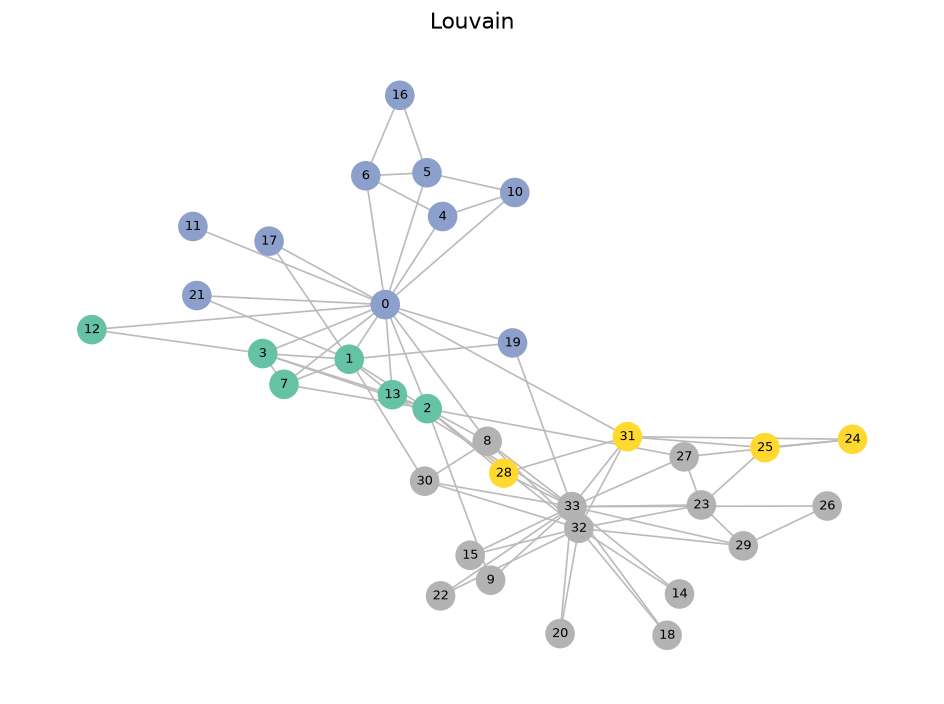

In [6]:
t0 = time.perf_counter()
louvain_parts = list(louvain_communities(karate, seed=42))
elapsed = time.perf_counter() - t0
results["Louvain"] = partition_stats(karate, louvain_parts) | {"time": elapsed}
print_stats("Louvain", results["Louvain"], elapsed)
draw_partition(karate, louvain_parts, pos, "Louvain", FIG / "louvain.png")


## Spectral Clustering (Fiedler, sweep cut)


Spectral: k=2, sizes=[17, 17], Q=0.3998, time=1.5144s


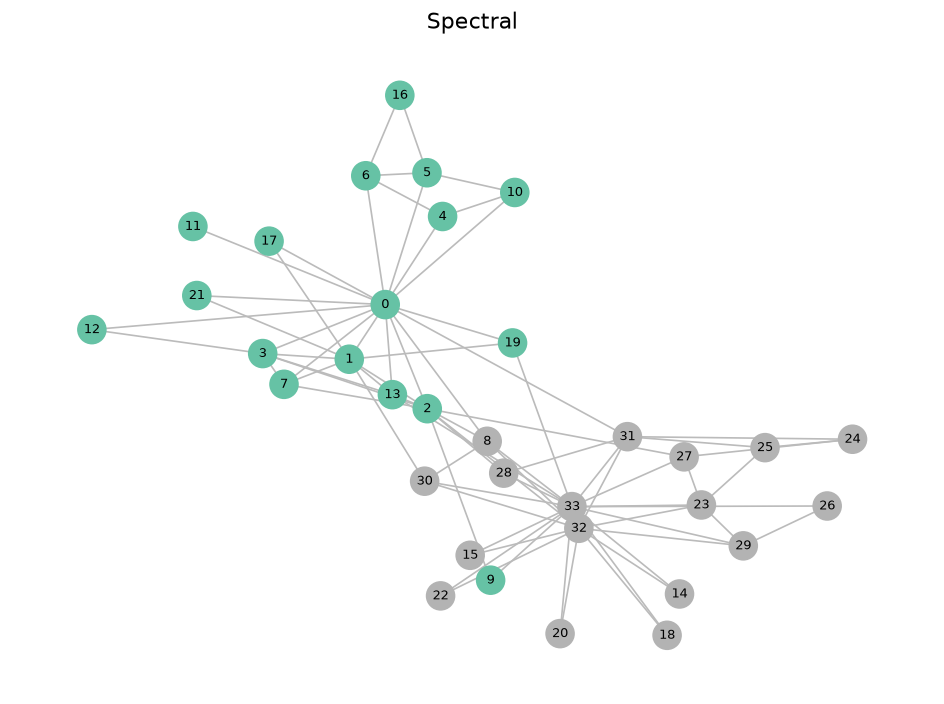

In [7]:
t0 = time.perf_counter()
spectral_parts = spectral_two_way(karate)
elapsed = time.perf_counter() - t0
results["Spectral"] = partition_stats(karate, spectral_parts) | {"time": elapsed}
print_stats("Spectral", results["Spectral"], elapsed)
draw_partition(karate, spectral_parts, pos, "Spectral", FIG / "spectral.png")


## Greedy Modularity


Greedy Modularity: k=3, sizes=[17, 9, 8], Q=0.4110, time=0.0057s


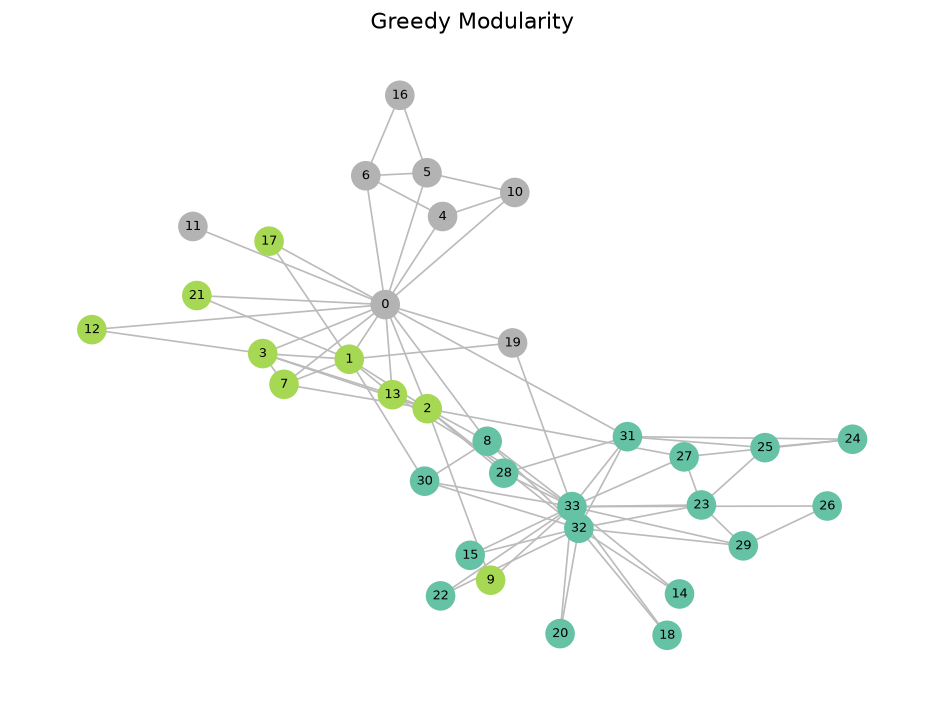

In [8]:
t0 = time.perf_counter()
greedy_parts = list(greedy_modularity_communities(karate))
elapsed = time.perf_counter() - t0
results["Greedy Modularity"] = partition_stats(karate, greedy_parts) | {"time": elapsed}
print_stats("Greedy Modularity", results["Greedy Modularity"], elapsed)
draw_partition(karate, greedy_parts, pos, "Greedy Modularity", FIG / "greedy_modularity.png")


## Girvan-Newman

Mỗi level gỡ tiếp các cạnh betweenness cao cho đến khi thêm một cụm. Thời gian in ra là thời gian thêm của level đó, không phải tổng từ đầu.


Girvan-Newman level 1: k=2, sizes=[19, 15], Q=0.3477, time=0.0289s


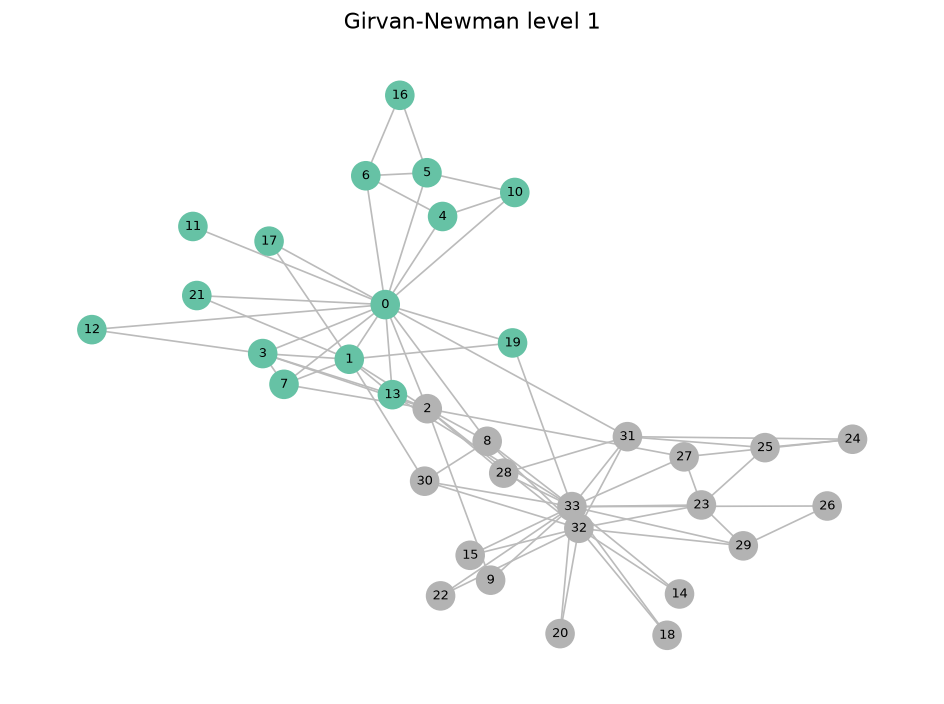

Girvan-Newman level 2: k=3, sizes=[18, 15, 1], Q=0.3423, time=0.0026s


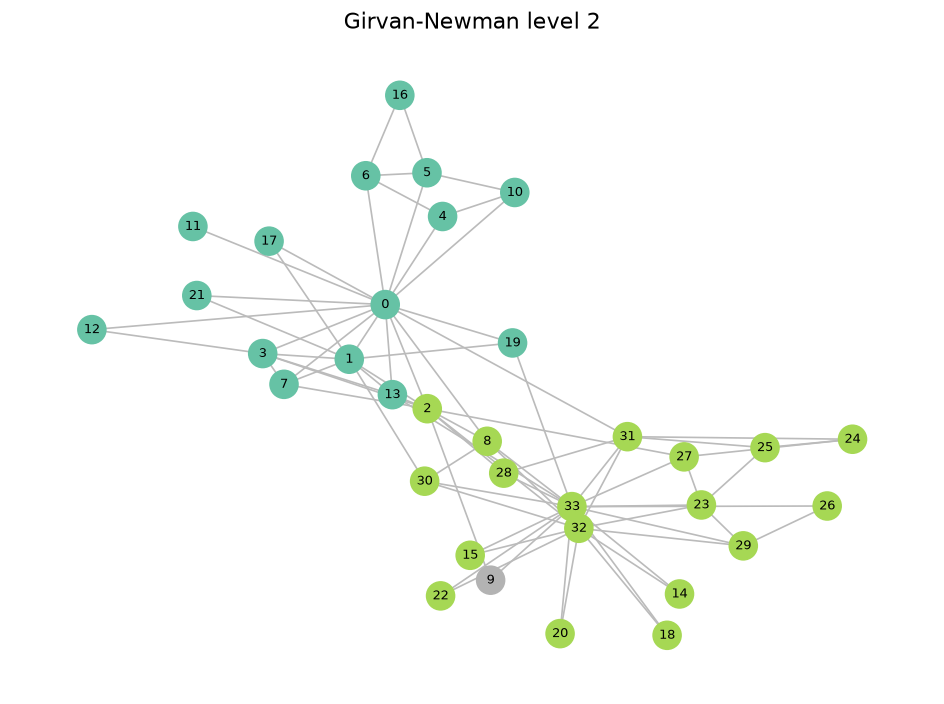

Girvan-Newman level 3: k=4, sizes=[18, 10, 5, 1], Q=0.3581, time=0.0091s


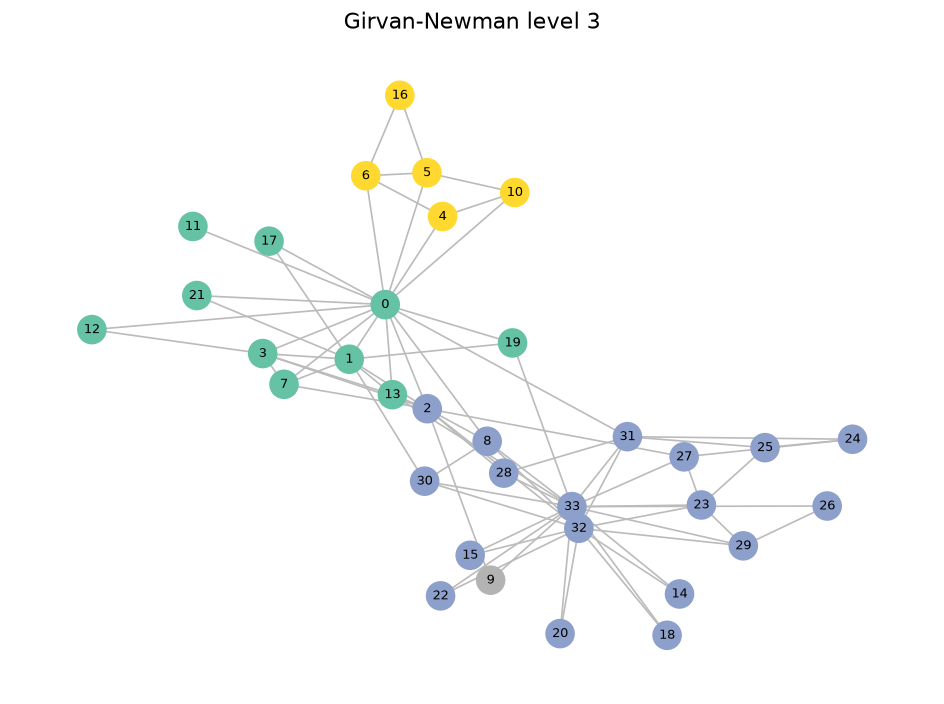

In [9]:
gn = girvan_newman(karate)
for level in range(1, 4):
    t0 = time.perf_counter()
    parts = [set(c) for c in next(gn)]
    elapsed = time.perf_counter() - t0
    label = f"Girvan-Newman level {level}"
    results[label] = partition_stats(karate, parts) | {"time": elapsed}
    print_stats(label, results[label], elapsed)
    draw_partition(karate, parts, pos, label, FIG / f"girvan-newman_level_{level}.png")


## Bảng so sánh


In [10]:
order = [
    "Label Propagation",
    "Louvain",
    "Spectral",
    "Greedy Modularity",
    "Girvan-Newman level 1",
    "Girvan-Newman level 2",
    "Girvan-Newman level 3",
]
rows = []
for name in order:
    st = results[name]
    rows.append([name, st["k"], st["sizes"], round(st["Q"], 4), round(st["time"], 4)])
summary = pd.DataFrame(rows, columns=["Method", "k", "sizes", "Q", "time (s)"])
print(summary.to_string(index=False))


               Method  k          sizes      Q  time (s)
    Label Propagation  3    [16, 15, 3] 0.3095    0.0039
              Louvain  4 [14, 10, 6, 4] 0.4266    0.0036
             Spectral  2       [17, 17] 0.3998    1.5144
    Greedy Modularity  3     [17, 9, 8] 0.4110    0.0057
Girvan-Newman level 1  2       [19, 15] 0.3477    0.0289
Girvan-Newman level 2  3    [18, 15, 1] 0.3423    0.0026
Girvan-Newman level 3  4 [18, 10, 5, 1] 0.3581    0.0091


## Xuất Gephi

File `karate_communities.gexf` mang thuộc tính `community` theo Louvain. Trong Gephi, tô màu nút theo thuộc tính đó thì bốn cụm hiện thành bốn màu.


In [11]:
export = karate.copy()
node2com = {}
for i, com in enumerate(results["Louvain"]["parts"]):
    for v in com:
        node2com[v] = i
nx.set_node_attributes(export, node2com, "community")
gexf_path = LAB / "karate_communities.gexf"
nx.write_gexf(export, gexf_path)
print(f"Exported: {gexf_path}")


Exported: d:\Study\IS353\BT\Lab5a\karate_communities.gexf


## 1. Compare results across all methods (Louvain, Spectral Clustering, Greedy Modularity, Girvan-Newman level 1-3, and Label Propagation) by number of communities, size, modularity, and running time.

### 1. So sánh các phương pháp theo số cụm, kích thước, modularity và thời gian chạy.

Câu hỏi ghi "number of components", nhưng đồ thị Karate Club chỉ có 1 connected component. Con số cần so là số community.

Phe lịch sử, lấy từ thuộc tính `club`, là mốc: 2 cụm, kích thước 17 và 17, Q = 0.3914. Bảng dưới là một lần chạy với Louvain `seed=42`. Q, k và kích thước cố định. Số giây đổi theo máy. Thời gian Girvan-Newman là thời gian thêm của từng level.

| Phương pháp | k | Kích thước | Q | Thời gian |
| --- | --- | --- | --- | --- |
| Label Propagation | 3 | 16, 15, 3 | 0.3095 | 0.001 s |
| Louvain | 4 | 14, 10, 6, 4 | 0.4266 | 0.002 s |
| Spectral | 2 | 17, 17 | 0.3998 | 0.70 s |
| Greedy Modularity | 3 | 17, 9, 8 | 0.4110 | 0.002 s |
| Girvan-Newman level 1 | 2 | 19, 15 | 0.3477 | 0.017 s |
| Girvan-Newman level 2 | 3 | 18, 15, 1 | 0.3423 | 0.002 s |
| Girvan-Newman level 3 | 4 | 18, 10, 5, 1 | 0.3581 | 0.003 s |

Louvain có Q cao nhất, 0.4266, vì nó cứ gộp cho đến khi modularity không tăng nữa, và dừng ở 4 cụm dày hơn là 2 phe. Greedy Modularity cùng hướng đó, Q = 0.4110, nhưng chỉ tách phe Mr. Hi, phe Officer gần như còn nguyên.

Spectral bị buộc cắt đúng 2 cụm. Q = 0.3998, vẫn cao hơn phe lịch sử. Nhát cắt cân bằng 17-17.

Girvan-Newman không tối ưu Q. Level 1 cũng ra 2 cụm nhưng lệch 19-15 và Q chỉ 0.3477. Level 2 tách thêm một đỉnh đơn (đỉnh 9) nên Q giảm xuống 0.3423. Level 3 tách nhóm 5 đỉnh khỏi phe Mr. Hi, Q nhích lên 0.3581, vẫn thấp hơn Spectral và Greedy.

Label Propagation không nhìn modularity. Nó ra 3 cụm và Q thấp nhất, 0.3095. Cụm 3 đỉnh là {5, 6, 16}, nhóm bạn sát đỉnh 0.

Trên 34 đỉnh, mọi phương pháp đều dưới 1 giây. Spectral trông chậm hơn vì phải giải vector riêng của Laplacian dày. So sánh tốc độ thật nằm ở câu 4.


## 2. Compare visually across all methods. What structural differences do you observe?

### 2. So sánh bằng hình: các cách cắt khác nhau chỗ nào?

Cùng một layout (`spring_layout`, seed 42). Chỉ màu cụm đổi.

![Label Propagation](figures/label_propagation.png)

![Louvain](figures/louvain.png)

![Spectral](figures/spectral.png)

![Greedy Modularity](figures/greedy_modularity.png)

![Girvan-Newman level 1](figures/girvan-newman_level_1.png)

![Girvan-Newman level 2](figures/girvan-newman_level_2.png)

![Girvan-Newman level 3](figures/girvan-newman_level_3.png)

Label Propagation nhìn thấy hai mảng lớn và một tam giác nhỏ {5, 6, 16} treo ở phe Mr. Hi. Vài đỉnh biên bị kéo nhầm phe: 24, 25, 31 sang phía Mr. Hi, còn 2 và 8 sang phía Officer.

Louvain cắt mỗi phe thành hai nhóm đặc. Phe Mr. Hi thành nhóm quanh 0 ({0, 4, 5, 6, 10, 11, 16, 17, 19, 21}) và nhóm quanh 1, 2, 3. Phe Officer tách {24, 25, 28, 31} ra khỏi nhóm quanh 33. Chỉ đỉnh 8 đứng khác phe lịch sử.

Spectral là một nhát cắt trái-phải. Khác phe lịch sử đúng hai đỉnh biên: 8 bị xếp cùng Officer, 9 bị xếp cùng Mr. Hi. Trên hình, 9 có màu phe 0 nhưng nằm sát cụm của 33.

Greedy giữ phe Officer gần nguyên khối (thêm đỉnh 8) và cắt đôi phe Mr. Hi. Đỉnh 9 nằm chung nhóm với 1, 2, 3.

Girvan-Newman level 1 cũng là hai phía, nhưng 2 và 8 còn kẹt bên Officer nên phía đó phình thành 19 đỉnh. Level 2 kéo đỉnh 9 ra thành cụm một mình. Level 3 cắt nốt {4, 5, 6, 10, 16} khỏi Mr. Hi. Càng về sau, thuật toán này bẻ các nhóm nhỏ và đỉnh biên, không giữ nguyên hai phe.


## 3. Which method best matches the intuitive split of the Karate Club? Why?

### 3. Phương pháp nào khớp lần tách hai phe của Karate Club nhất? Vì sao?

Spectral khớp nhất.

Câu chuyện của đồ thị này là một câu lạc bộ tách làm hai, quanh huấn luyện viên (0) và chủ tịch (33), mỗi bên 17 người. Spectral trả về đúng 2 cụm, mỗi cụm 17 đỉnh. So với thuộc tính `club`, chỉ hai đỉnh bị đổi chỗ: 8 và 9. Cả hai đều nằm trên biên giữa hai phe. Q của nhát cắt này là 0.3998, còn Q của phe ghi trong dữ liệu là 0.3914, nên đây cũng là cách cắt đôi tốt hơn một chút so với lần tách thật.

Girvan-Newman level 1 cũng ra 2 cụm, nhưng kích thước 19 và 15, Q chỉ 0.3477, và đẩy cả đỉnh 2 lẫn đỉnh 8 sang phe Officer. Khớp câu chuyện hơn Louvain, nhưng kém Spectral.

Louvain có Q cao nhất (0.4266) nhưng ra 4 cụm. Nó tìm các nhóm bạn dày bên trong từng phe, không phải lần câu lạc bộ vỡ làm hai. Greedy thì mới cắt một phe. Label Propagation vừa trộn đỉnh biên vừa tách một tam giác nhỏ, Q thấp nhất.

Muốn kể đúng chuyện hai thủ lĩnh thì lấy Spectral. Muốn Q cao nhất thì lấy Louvain, và chấp nhận cụm mịn hơn câu chuyện.


## 4. (Extra) Re-run on the Facebook dataset. Which method scaled best, and what patterns did you see?

### 4. (Thêm) Chạy lại trên ego-Facebook. Phương pháp nào chịu được đồ thị lớn, và thấy cấu trúc gì?

Ô dưới đọc `facebook_combined.txt` (4039 đỉnh, 88234 cạnh, 1 component). Greedy Modularity mất khoảng 15 giây. Girvan-Newman không chạy: mỗi lần gỡ một cạnh phải tính betweenness của mọi cạnh, trên 88234 cạnh thì không xong trong lab này.


In [12]:
fb_candidates = [
    LAB.parent / "Lab1_2" / "facebook_combined.txt",
    LAB.parent / "Lab3" / "facebook_combined.txt",
    LAB.parent / "Lab4" / "facebook_combined.txt",
    Path.cwd() / "facebook_combined.txt",
]
fb_path = next(path for path in fb_candidates if path.exists())
print(f"Đọc {fb_path}")
facebook = nx.read_edgelist(fb_path, nodetype=int)
print(f"Facebook: {facebook.number_of_nodes()} nodes, {facebook.number_of_edges()} edges")

fb_rows = []


def run_fb(label, fn):
    t0 = time.perf_counter()
    parts = fn()
    elapsed = time.perf_counter() - t0
    st = partition_stats(facebook, parts)
    print_stats(label, st, elapsed)
    print(f"  top sizes: {st['sizes'][:8]}")
    fb_rows.append([label, st["k"], st["sizes"][:5], round(st["Q"], 4), round(elapsed, 2)])


run_fb("Label Propagation", lambda: list(label_propagation_communities(facebook)))
run_fb("Louvain", lambda: list(louvain_communities(facebook, seed=42)))
run_fb("Spectral", lambda: spectral_two_way(facebook))
run_fb("Greedy Modularity", lambda: list(greedy_modularity_communities(facebook)))
print("Girvan-Newman: bỏ qua, edge betweenness trên 88234 cạnh.")
print(pd.DataFrame(fb_rows, columns=["Method", "k", "top sizes", "Q", "time (s)"]).to_string(index=False))


Đọc d:\Study\IS353\BT\Lab1_2\facebook_combined.txt
Facebook: 4039 nodes, 88234 edges
Label Propagation: k=44, sizes=[1030, 753, 547, 469, 226, 215, 198, 179, 60, 49, 36, 34, 25, 19, 16, 14, 13, 12, 10, 10, 10, 9, 9, 8, 8, 8, 8, 7, 7, 6, 6, 6, 4, 3, 3, 3, 3, 3, 3, 2, 2, 2, 2, 2], Q=0.7368, time=0.9675s
  top sizes: [1030, 753, 547, 469, 226, 215, 198, 179]
Louvain: k=16, sizes=[548, 535, 435, 431, 423, 350, 324, 237, 226, 206, 128, 73, 60, 25, 19, 19], Q=0.8349, time=1.3121s
  top sizes: [548, 535, 435, 431, 423, 350, 324, 237]
Spectral: k=2, sizes=[2998, 1041], Q=0.4699, time=3.6319s
  top sizes: [2998, 1041]
Greedy Modularity: k=13, sizes=[983, 815, 548, 543, 372, 219, 208, 206, 59, 37, 25, 18, 6], Q=0.7774, time=23.4629s
  top sizes: [983, 815, 548, 543, 372, 219, 208, 206]
Girvan-Newman: bỏ qua, edge betweenness trên 88234 cạnh.
           Method  k                  top sizes      Q  time (s)
Label Propagation 44 [1030, 753, 547, 469, 226] 0.7368      0.97
          Louvain 16  [548

Một lần đo, Louvain `seed=42`. Q và số cụm cố định, số giây đổi theo máy.

| Phương pháp | k | Vài kích thước đầu | Q | Thời gian |
| --- | --- | --- | --- | --- |
| Label Propagation | 44 | 1030, 753, 547, 469, 226 | 0.7368 | 0.25 s |
| Louvain | 16 | 548, 535, 435, 431, 423 | 0.8349 | 0.54 s |
| Spectral | 2 | 2998, 1041 | 0.4699 | 2.53 s |
| Greedy Modularity | 13 | 983, 815, 548, 543, 372 | 0.7774 | 14.8 s |

Louvain chịu đồ thị này tốt nhất nếu tính cả chất lượng lẫn thời gian: khoảng nửa giây, Q cao nhất 0.8349, 16 cụm kích thước gần nhau. Label Propagation nhanh hơn một chút (0.25 s) nhưng Q thấp hơn và có một cụm 1030 đỉnh, tức là dính nhiều vòng bạn vào một nhóm. Greedy cùng họ tối ưu modularity, Q = 0.7774, nhưng chậm hơn Louvain khoảng 30 lần. Spectral chỉ được cắt đôi, Q = 0.4699, thấp hơn hẳn: một nhát cắt không mô tả được đồ thị này.

Cấu trúc nhìn thấy được là nhiều vòng bạn, không phải hai phe như Karate Club. ego-Facebook là hợp của nhiều ego-network. Bạn của cùng một người tụ thành từng circle. Louvain tách khoảng 16 circle và Q vẫn trên 0.83, nghĩa là cạnh nằm trong circle nhiều hơn rất nhiều so với cạnh bắt cầu giữa các circle. Girvan-Newman hợp với đồ thị nhỏ vì nó chỉ ra từng cạnh cầu, nhưng không scale khi số cạnh lên tới hàng chục nghìn.
